## LAB 4 - TASK 3 submission. ML 2025-26
FILL UP THIS BOX WITH YOUR DETAILS

**NAME AND NIP**: Jorge Ruiz (826685) and Hugo López (875455)

## 3. Fine-tunning
Now we going to fine-tune a well known CNN architecture for image classification that has already been trained in ImageNet. We are going to fine-tune this for our own toy-dataset.

## Get data and tensorflow imports ready



In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras import backend as K

from tensorflow.keras import optimizers
from tensorflow.keras.applications import VGG16

import matplotlib.pyplot as plt

In [ ]:
# GET YOUR IMAGES READY

# OPTION A: upload and unzip, untar ... images if necessary (not recommended ... it'll only last one session)
from google.colab import files, drive
# uploaded = files.upload()
drive.mount('/content/drive')
# 'uploaded' is a dictionary. You can get the file content like this:
# for filename, content in uploaded.items():
#     print(f"Uploaded {filename} with {len(content)} bytes")
# #!tar -xvzf images.tar.gz
# !unzip toy-data.zip
# !ls

import os
drive_data_path = '/content/drive/MyDrive/IA_p3_images/'
if os.path.exists(drive_data_path):
    print("Found Google Drive image directory! Classes:")
    print(os.listdir(drive_data_path))
else:
    print(f"Could not find directory: {drive_data_path}. Please verify the path names inside '/content/drive/MyDrive/'.")

# OPTION B: mount your google drive to point the code to find the data in your drive folders
# (instructions here: https://colab.research.google.com/notebooks/io.ipynb#scrollTo=u22w3BFiOveA)
# from google.colab import drive
# drive.mount('/content/drive')
# This assumes your file is in your main "My Drive" folder
# Adjust the path as needed! This will mount the data into a folder on a local drive for faster access
# !unzip "/content/drive/My Drive/your_dataset_name.zip" -d "/content/dataset"

Mounted at /content/drive
Found Google Drive image directory! Classes:
['cheesecake', 'chicken_quesadilla', 'chicken_wings', 'churros', 'donuts']


In [ ]:
# # SOME HELPER FUNCTIONS TO VISUALIZE RESULTS
# def vis_history(results_history):
#     acc = results_history.history['accuracy']
#     val_acc = results_history.history['val_accuracy']

#     loss = results_history.history['loss']
#     val_loss = results_history.history['val_loss']

#     epochs_range = range(epochs)

#     plt.figure(figsize=(16, 8))
#     plt.subplot(1, 2, 1)
#     plt.plot(epochs_range, acc, label='Training Accuracy')
#     plt.plot(epochs_range, val_acc, label='Validation Accuracy')
#     plt.legend(loc='lower right')
#     plt.title('Training and Validation Accuracy')

#     plt.subplot(1, 2, 2)
#     plt.plot(epochs_range, loss, label='Training Loss')
#     plt.plot(epochs_range, val_loss, label='Validation Loss')
#     plt.legend(loc='upper right')
#     plt.title('Training and Validation Loss')
#     plt.show()

In [ ]:
# SOME HELPER FUNCTIONS TO VISUALIZE RESULTS
def vis_history(results_history, epochs=10):
    acc = results_history.history['accuracy']
    val_acc = results_history.history['val_accuracy']

    loss = results_history.history['loss']
    val_loss = results_history.history['val_loss']

    epochs_range = range(epochs)

    plt.figure(figsize=(16, 8))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()

In [ ]:
####### ***** TO-DO-LAB *****  #######
# make sure you config these params to fit what you want/need to LOAD YOUR DATA
# dimensions we will use with our images (they'll be resized if not this shape)
img_width, img_height = 224, 224 # TO MATCH THE SIZES OF THE BASE MODEL WE WANT TO USE, MOBILENET
# MODIFY THE PATH TO POINT TO YOUR DATA! locally here or in your mounted drive
# data_dir = './images/' # all in one folder and let the system do the split
data_dir = drive_data_path
batch_size = 4
num_classes = 5
####### ***** TO-DO-LAB *****  #######

if K.image_data_format() == 'channels_first':
    input_shape = (3, img_width, img_height)
else:
    input_shape = (img_width, img_height, 3)

train_ds, val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="both",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# for more optimized handling of the data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 5000 files belonging to 5 classes.
Using 4000 files for training.
Using 1000 files for validation.


## Let's do the fine-tunning


Let's load the base model, and modify the final classification layers to adapt to our 5-class toy-dataset. In this example we are fine-tuning MobileNetV2.

There are plenty of base models you could use, this is a pretty good compromise quality vs speed. Many more models in: https://www.tensorflow.org/api_docs/python/tf/keras/applications

In [ ]:
# weights = 'imagenet' is saying we want to upload the model ALREADY TRAINED in Imagenet
# THIS IS ESSENTIAL! otherwise we will just be training the architecture from scratch
IMG_SHAPE = (img_width, img_height) + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')


# We use the preprocessing method included with the model (for consistency with the pre-trained model we are using)
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
# apply data augmentation
data_augmentation = tf.keras.Sequential(
  [
    layers.RandomFlip("horizontal", input_shape=IMG_SHAPE),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
  ]
)
# let's define our last layer depending on the number of classes we want to classify
prediction_layer = tf.keras.layers.Dense(5)

# Differently from previous example, in this cases it's more convenient
# to build our model using the Keras Model API (https://keras.io/api/models/)
inputs = tf.keras.Input(shape=(img_width, img_height, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
# The base model contains batchnorm layers. It is ESSENTIAL TO SET IT AS inference mode
# SO when we unfreeze the base model for fine-tuning the batchnorm information is not distroyed
# So, we make sure that the base_model is running in inference mode here.
# more details on this in fine-tuning tutorial: https://www.tensorflow.org/guide/keras/transfer_learning
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)


print("Let's leave the original model frozen for now ...")
# FREEZE the base model
base_model.trainable = False
for i, layer in enumerate(model.layers):
   print(i, layer.name, layer.trainable)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Let's leave the original model frozen for now ...
0 input_layer_2 True
1 sequential True
2 mobilenetv2_1.00_224 False
3 global_average_pooling2d True
4 dropout True
5 dense True


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1049s 360ms/step - accuracy: 0.8167 - loss: 0.5214 - val_accuracy: 0.8970 - val_loss: 0.2888
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 238s 238ms/step - accuracy: 0.8907 - loss: 0.3191 - val_accuracy: 0.9120 - val_loss: 0.2646
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 240s 240ms/step - accuracy: 0.8990 - loss: 0.3005 - val_accuracy: 0.9080 - val_loss: 0.3104
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 237s 237ms/step - accuracy: 0.9072 - loss: 0.2631 - val_accuracy: 0.9130 - val_loss: 0.2766
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 235s 235ms/step - accuracy: 0.9085 - loss: 0.2636 - val_accuracy: 0.9140 - val_loss: 0.2868
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 236s 236ms/step - accuracy: 0.9118 - loss: 0.2616 - val_accuracy: 0.9050 - val_loss: 0.3365
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 233s 233ms/step - accuracy: 0.9215 - loss: 0.2461 - val_accuracy: 0.9000 - val_loss: 0.3309
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 237s 238ms/step - a

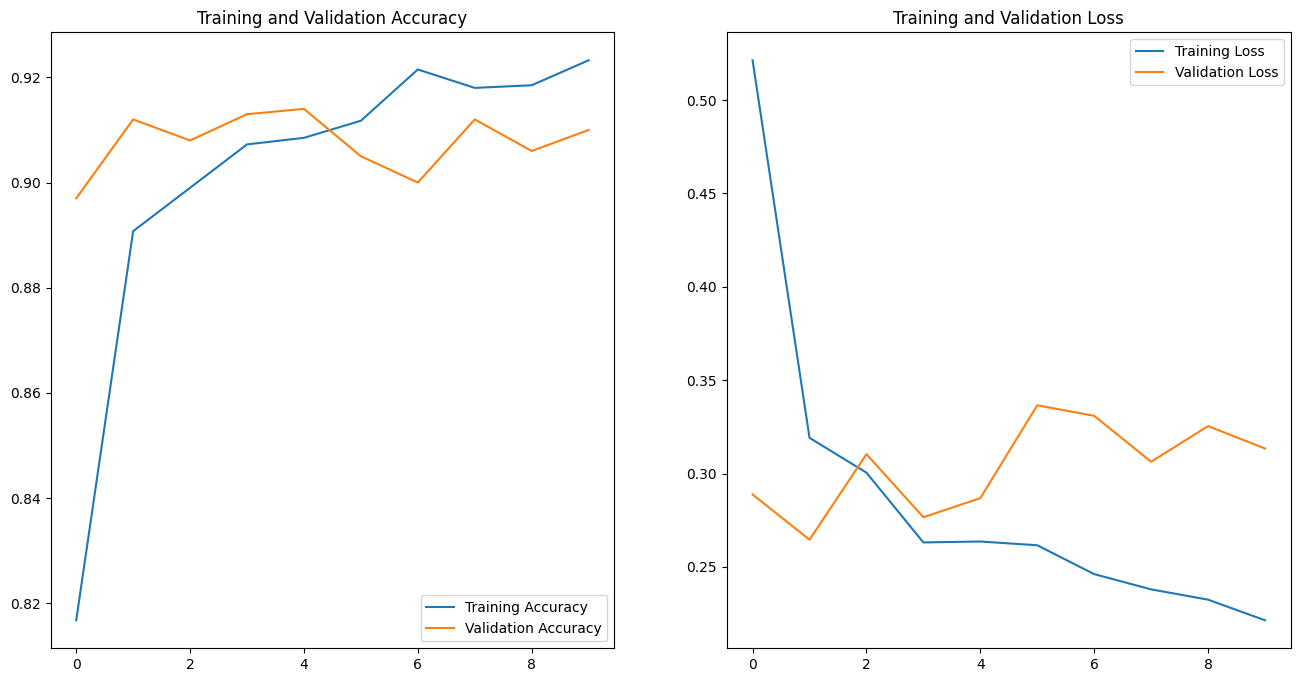

In [ ]:
base_learning_rate = 0.001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.summary()

epochs = 10 # UPDATE WITH YOUR NUMBERS!!
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

vis_history(history)

In [ ]:
# first: train only the top layers (which were randomly initialized)
# i.e. freeze all base model layers
print("And now let's enable trainable flag to the BASE MODEL: ")
base_model.trainable = True
for i, layer in enumerate(model.layers):
   print(i, layer.name, layer.trainable)

And now let's enable trainable flag to the BASE MODEL: 
0 input_layer_2 True
1 sequential True
2 mobilenetv2_1.00_224 True
3 global_average_pooling2d True
4 dropout True
5 dense True


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 2,230,277 (8.51 MB)

 Non-trainable params: 34,112 (133.25 KB)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 106s 80ms/step - accuracy: 0.7078 - loss: 0.9138 - val_accuracy: 0.8860 - val_loss: 0.4107
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 80s 80ms/step - accuracy: 0.7980 - loss: 0.5698 - val_accuracy: 0.9040 - val_loss: 0.3638
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 80s 80ms/step - accuracy: 0.8475 - loss: 0.4369 - val_accuracy: 0.8730 - val_loss: 0.5079
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 77s 77ms/step - accuracy: 0.8690 - loss: 0.3713 - val_accuracy: 0.8390 - val_loss: 0.5874
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 78s 78ms/step - accuracy: 0.8980 - loss: 0.2984 - val_accuracy: 0.7760 - val_loss: 0.8706
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 82s 78ms/step - accuracy: 0.9135 - loss: 0.2440 - val_accuracy: 0.7030 - val_loss: 1.4602
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 78s 78ms/step - accuracy: 0.9250 - loss: 0.2122 - val_accuracy: 0.7300 - val_loss: 1.2210
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 77s 77ms/step - accuracy: 0.9315 

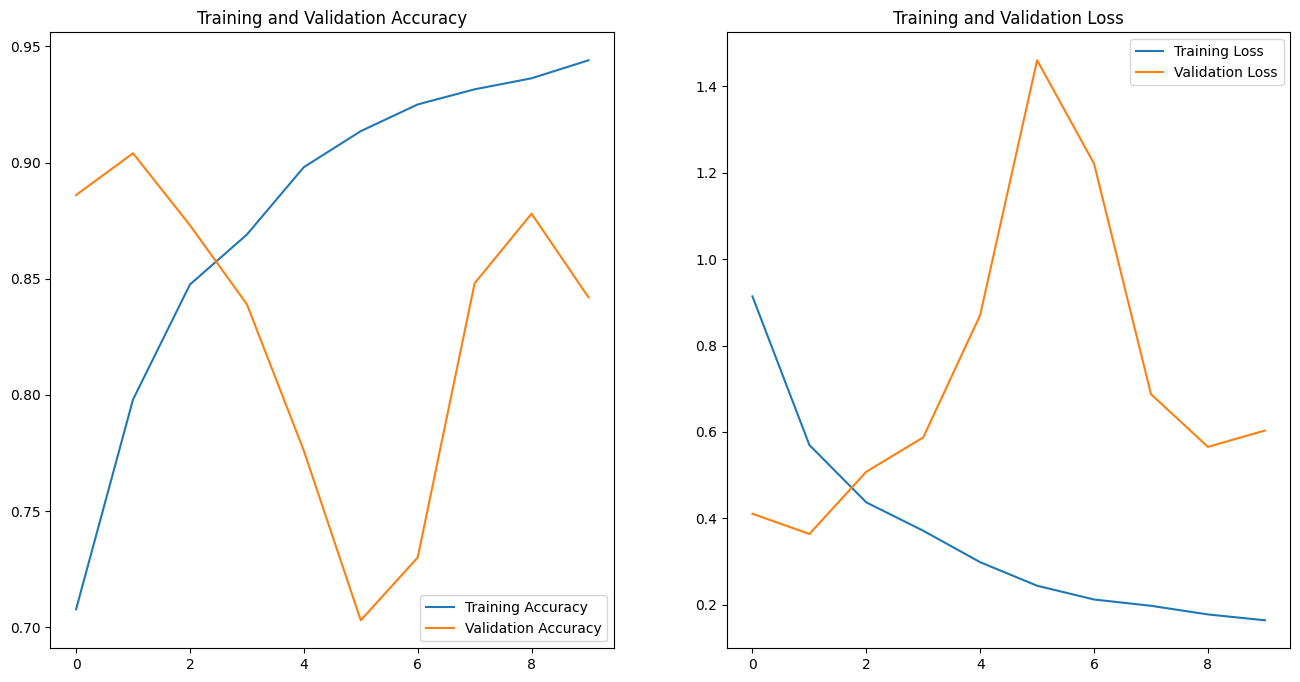

In [ ]:
epochs = 10 # UPDATE WITH YOUR NUMBERS!!

base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.summary()
history2 = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)
vis_history(history2)

# Save the model
model.save('last_finetuned_model_V1.keras')

As a **final experiment, run a few (ONLY 2 or 3) variations to see HOW/IF your changes influence the results**.
- You can change learning rates (where do you think it makes sense to use smaller? larger?), optimizers, batch size, ...
- INSTEAD of just SAVING THE LAST MODEL. you can add this callback to save "check points" of your model (in this case is set to save only the best one found).
More info: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ModelCheckpoint

You can add plenty of other "utilities" to run during your training process.
More info: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks

In [ ]:
checkpoint_filepath = './tmp/checkpoint.weights.h5'
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='accuracy',
    mode='max',
    save_best_only=True)

# Model weights are saved at the end of every epoch, if it's the best seen
# so far.
#history2 = model.fit(
#  train_ds,
#  validation_data=val_ds,
#  epochs=epochs,
#  callbacks=[model_checkpoint_callback]
#)


In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model.keras",
        monitor="accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9613 - loss: 0.1267
Epoch 1: val_loss improved from None to 1.10844, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 83s 83ms/step - accuracy: 0.9580 - loss: 0.1270 - val_accuracy: 0.7790 - val_loss: 1.1084 - learning_rate: 1.0000e-04
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9654 - loss: 0.1039
Epoch 2: val_loss improved from 1.10844 to 0.54916, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 83s 83ms/step - accuracy: 0.9582 - loss: 0.1229 - val_accuracy: 0.8680 - val_loss: 0.5492 - learning_rate: 1.0000e-04
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9697 - loss: 0.0830
Epoch 3: val_loss did not improve from 0.54916
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 79s 79ms/step - accuracy: 0.9643 - loss: 0.1100 - val_accuracy: 0.8150 - val_loss: 0.8

In [ ]:
best_model_1 = tf.keras.models.load_model("best_model.keras")


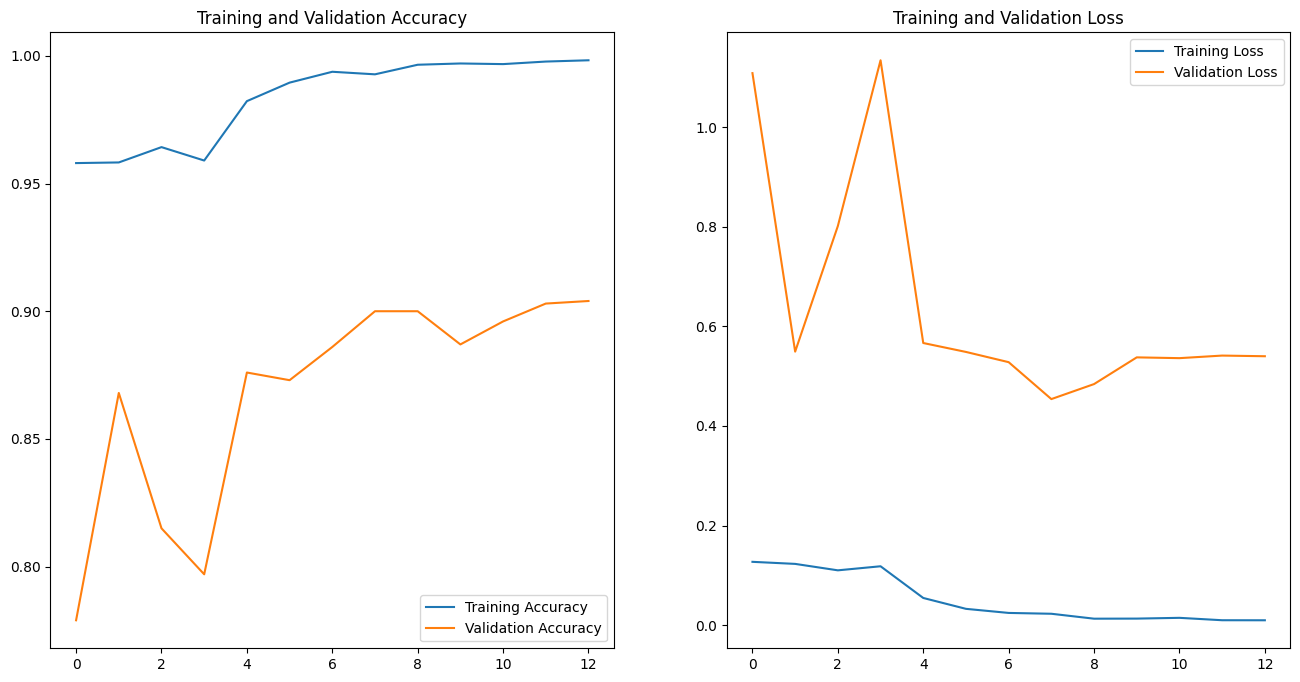

In [ ]:
vis_history(history, 13)

In [ ]:
# Initial training: feature extractor frozen
base_model.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_22 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)

vis_history(history_22, 40)



Epoch 1/40
 997/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9784 - loss: 0.2032
Epoch 1: val_loss did not improve from 0.45387
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9783 - loss: 0.2673 - val_accuracy: 0.8970 - val_loss: 0.8598 - learning_rate: 0.0010
Epoch 2/40
 999/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9756 - loss: 0.3997
Epoch 2: val_loss did not improve from 0.45387

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9725 - loss: 0.4654 - val_accuracy: 0.8880 - val_loss: 0.8878 - learning_rate: 0.0010
Epoch 3/40
 998/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9720 - loss: 0.6584
Epoch 3: val_loss did not improve from 0.45387
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9753 - loss: 0.6709 - val_accuracy: 0.8930 - val_loss: 0.9040 - learning_rate: 2.0000e-04
Epoch 4/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9713 -

TypeError: vis_history() takes 1 positional argument but 2 were given

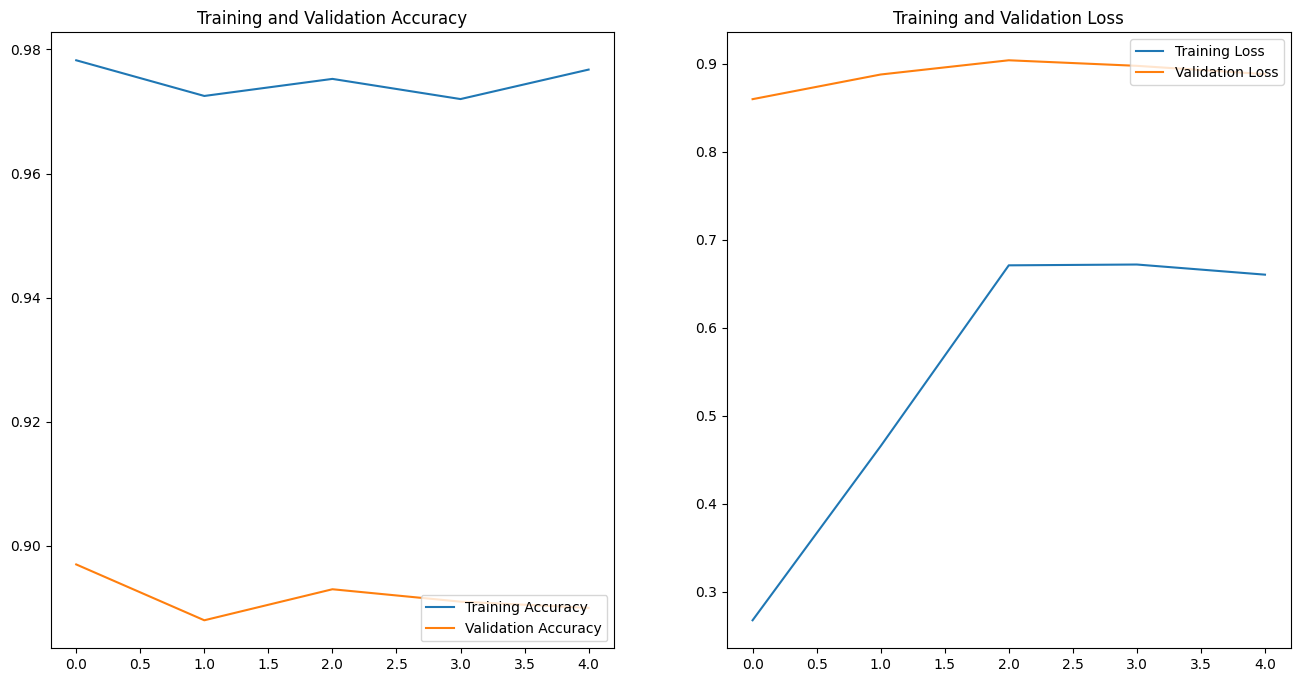

In [ ]:

vis_history(history_22, 5)



Epoch 1/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9740 - loss: 0.3686
Epoch 1: val_loss did not improve from 0.45387
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - accuracy: 0.9753 - loss: 0.3834 - val_accuracy: 0.8900 - val_loss: 0.7842 - learning_rate: 1.0000e-05
Epoch 2/40
 998/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9628 - loss: 0.4818
Epoch 2: val_loss did not improve from 0.45387

Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.9572 - loss: 0.5424 - val_accuracy: 0.8720 - val_loss: 0.8630 - learning_rate: 1.0000e-05
Epoch 3/40
 999/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9539 - loss: 0.6063
Epoch 3: val_loss did not improve from 0.45387
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.9580 - loss: 0.5747 - val_accuracy: 0.8710 - val_loss: 0.8449 - learning_rate: 2.0000e-06
Epoch 4/40
 998/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 

ValueError: x and y must have same first dimension, but have shapes (40,) and (5,)

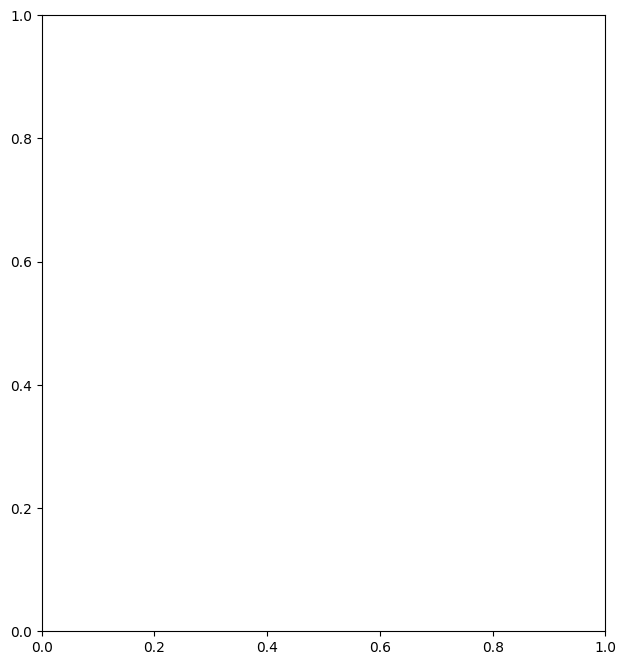

In [ ]:
base_model.trainable = True

# Keep most layers frozen
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Usually keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_33 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)

vis_history(history_33, 40)

With data augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

In [ ]:
inputs = tf.keras.Input(shape=input_shape)
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_44 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)

vis_history(history_44, 40)

### **QUESTION 1**. Answer True/False and explain why you think so.

1. After reading the explanations in this notebook, I think when fine-tuning and existing model, we usually start with its layers frozen, but later we should un-freeze *ALL* layers always.

2.   It is essential to make sure when loading the base model, its parameter *weights* are initialized to the pre-trained weigths we want, usually imagenet.

ANSWER 1: [YOUR ANSWER HERE]

### **QUESTION 2**.
Discuss the results you have obtained with your toy-data after running the different steps of the fine tunning process and the variations you have incorporated.

* How does it compare to the previous tasks in this Lab? What are advantages/disadvantages you find within each option? (max 10 lines).





ANSWER 2: [YOUR ANSWER HERE]



|Method	| Advantages |	Disadvantages|
| --- | --- | --- |
|2NN	|- ??. <br> - ??. |	- ??. <br> - ??. |
|CNN Simple	|- ??. |	- ??. <br> - ??. |
|Fine-Tuning |	- ??. <br> - ??. |	- ??.  <br> - ??.|